In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
import numpy as np

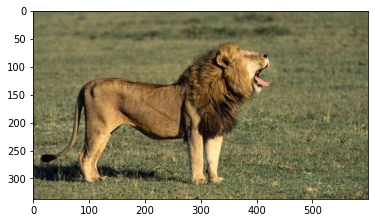

In [6]:
path = 'lion.jpeg'
img = mpimg.imread(path)
imgplot  = plt.imshow(img)

In [8]:
img.shape

(337, 600, 3)

In [10]:
dims  = img.shape

R = np.zeros((dims[0], dims[1]),int)
G = np.zeros((dims[0], dims[1]),int)
B = np.zeros((dims[0], dims[1]),int)

In [11]:
R1 = img[:,:,0]

In [12]:
for i in range(dims[0]):
    R[i,:] = img[i,:,0]
    G[i,:] = img[i,:,1]
    B[i,:] = img[i,:,2]

In [13]:
print(R1.shape)
print(R.shape)
print(G.shape)

(337, 600)
(337, 600)
(337, 600)


In [14]:
from scipy import linalg

In [15]:
U0,s0,V0 = linalg.svd(R)
U1,s1,V1 = linalg.svd(G)
U2,s2,V2 = linalg.svd(B)

In [16]:
print(U0.shape, s0.shape, V0.shape)

(337, 337) (337,) (600, 600)


In [18]:
rank1_R = U0[:,0].reshape(len(U0[:,0]),1) * s0[0] * V0[0,:]
rank1_G = U1[:,0].reshape(len(U1[:,0]),1) * s1[0] * V1[0,:]
rank1_B = U2[:,0].reshape(len(U2[:,0]),1) * s2[0] * V2[0,:]

In [19]:
rank1_R.shape

(337, 600)

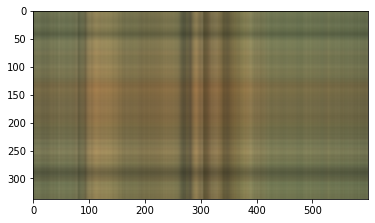

In [20]:
rank1_app = np.zeros(dims,int)

for i in range(dims[0]):
    rank1_app[i,:,0] = rank1_R[i,:]
    rank1_app[i,:,1] = rank1_G[i,:]
    rank1_app[i,:,2] = rank1_B[i,:]
    
plt.imshow(rank1_app)

In [19]:
print(U0[:,0].reshape(len(U0[:,0]),1).shape)

(337, 1)


In [22]:
print(s0[0])

53626.501420315275


In [21]:
print(V0[0,:].shape)

(600,)


In [26]:
rank1_R = U0[:,0].reshape(len(U0[:,0]),1) * s0[0] * V0[0,:]
rank1_G = U1[:,0].reshape(len(U1[:,0]),1) * s1[0] * V1[0,:]
rank1_B = U2[:,0].reshape(len(U2[:,0]),1) * s2[0] * V2[0,:]

rank2_R = U0[:,1].reshape(len(U0[:,0]),1) * s0[1] * V0[1,:]
rank2_G = U1[:,1].reshape(len(U1[:,0]),1) * s1[1] * V1[1,:]
rank2_B = U2[:,1].reshape(len(U2[:,0]),1) * s2[1] * V2[1,:]

rank3_R = U0[:,2].reshape(len(U0[:,0]),1) * s0[2] * V0[2,:]
rank3_G = U1[:,2].reshape(len(U1[:,0]),1) * s1[2] * V1[2,:]
rank3_B = U2[:,2].reshape(len(U2[:,0]),1) * s2[2] * V2[2,:]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


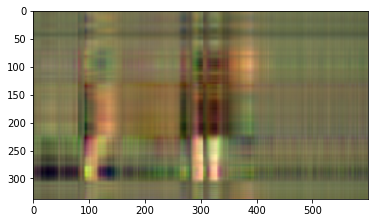

In [27]:
rank3_app = np.zeros(dims,int)

for i in range(dims[0]):
    rank3_app[i,:,0] = rank1_R[i,:] + rank2_R[i,:] + rank3_R[i,:]
    rank3_app[i,:,1] = rank1_G[i,:] + rank2_G[i,:] + rank3_G[i,:]
    rank3_app[i,:,2] = rank1_B[i,:] + rank2_B[i,:] + rank3_B[i,:]
    
plt.imshow(rank3_app)

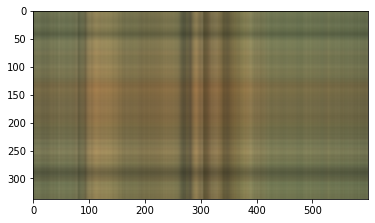

In [21]:
plt.imshow(rank1_app)

In [22]:
# U0,s0,V0
# U1,s1,V1
# U2,s2,V2

In [23]:
# indices

i0 = np.argsort(-s0)
i1 = np.argsort(-s1)
i2 = np.argsort(-s2)

In [24]:
U0_s = U0[:,i0]
U1_s = U1[:,i1]
U2_s = U2[:,i2]

In [25]:
V0_s = V0[i0,:]
V1_s = V1[i1,:]
V2_s = V2[i2,:]

In [26]:
s0_s = s0[i0]
s1_s = s1[i1]
s2_s = s2[i2]

In [27]:
rank = 15

img_0 = U0_s[:,:rank] @ np.diag(s0_s[:rank]) @ V0_s[:rank,:]
img_1 = U1_s[:,:rank] @ np.diag(s1_s[:rank]) @ V1_s[:rank,:]
img_2 = U2_s[:,:rank] @ np.diag(s2_s[:rank]) @ V2_s[:rank,:]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


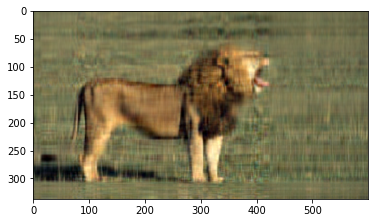

In [37]:
img_10rank = np.round(np.zeros(list(img_0.shape)+[3])).astype(int)

img_10rank[:,:,0]=img_0
img_10rank[:,:,1]=img_1
img_10rank[:,:,2]=img_2

plt.imshow(img_10rank)